# **Minor Project 3**

# **Minor Project 1: Sales Performance Analysis System**

## **1. Problem Statement**


   Organizations collect large amounts of sales data, but they may not clearly understand overall sales performance, sales trends, or the contribution of different product categories. This project analyzes sales data using Python to identify useful patterns and present the results through charts and summary statistics.

## **2. Tools and Libraries**


- **Python** – programming and analysis
- **Pandas** – data loading, cleaning, grouping, and summary statistics
- **Matplotlib** – charts and visualizations
- **Seaborn** – count plot for transaction distribution

## **3. Dataset Description**


The dataset contains sales transaction records with fields such as order ID, order date, customer, location, product category, product name, quantity, unit price, revenue, and profit.

## **4. Step 1 - Import Required Libraries**

The libraries below are used to load, process, analyze, and visualize the sales data.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Improve the appearance of charts
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## **5. Step 2 - Load the Dataset**


In [ ]:
file_path = "product_sales_dataset_final_minor_project_3.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Number of rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully.
Number of rows and columns: (200000, 14)


,Order_ID,Order_Date,Customer_Name,City,State,Region,Country,Category,Sub_Category,Product_Name,Quantity,Unit_Price,Revenue,Profit
0,1,08-23-23,Bianca Brown,Jackson,Mississippi,South,United States,Accessories,Small Electronics,Phone Case,3,201.01,603.03,221.49
1,2,12-20-24,Jared Edwards,Grand Rapids,Michigan,Centre,United States,Accessories,Small Electronics,Charging Cable,4,74.30,297.20,97.09
2,3,01-29-24,Susan Valdez,Minneapolis,Minnesota,Centre,United States,Clothing & Apparel,Sportswear,Nike Air Force 1,1,68.19,68.19,25.47
3,4,11-29-24,Tina Williams,Tallahassee,Florida,South,United States,Clothing & Apparel,Sportswear,Adidas Tracksuit,3,209.64,628.92,231.38
4,5,09-21-23,Catherine Gordon,Baltimore,Maryland,East,United States,Accessories,Bags,Backpack,1,216.63,216.63,42.46


## **6. Step 3 - Inspect the Dataset**

This step displays column names, data types, dataset size, and descriptive statistics. It helps us understand the structure of the data before analysis.

In [ ]:
print("Dataset shape:", df.shape)

print("Column names:")
print(df.columns.tolist())
print("\n")

print("Dataset information:")
df.info()
print("\n")

print("Descriptive statistics:")
display(df.describe(include="all").T)
print("\n")

Dataset shape: (200000, 14)
Column names:
['Order_ID', 'Order_Date', 'Customer_Name', 'City', 'State', 'Region', 'Country', 'Category', 'Sub_Category', 'Product_Name', 'Quantity', ' Unit_Price ', ' Revenue ', ' Profit ']


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Order_ID       200000 non-null  int64  
 1   Order_Date     200000 non-null  object 
 2   Customer_Name  200000 non-null  object 
 3   City           200000 non-null  object 
 4   State          200000 non-null  object 
 5   Region         200000 non-null  object 
 6   Country        200000 non-null  object 
 7   Category       200000 non-null  object 
 8   Sub_Category   200000 non-null  object 
 9   Product_Name   200000 non-null  object 
 10  Quantity       200000 non-null  int64  
 11   Unit_Price    200000 non-null  float64
 12   Revenue  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,200000.0,NaN,NaN,NaN,100000.5,57735.171256,1.0,50000.75,100000.5,150000.25,200000.0
Order_Date,200000,731,11-24-23,1070,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,200000,120230,Michael Smith,102,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,200000,108,Pittsburgh,2932,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,200000,47,California,10272,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,200000,4,East,57034,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,200000,1,United States,200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,200000,4,Clothing & Apparel,62298,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sub_Category,200000,19,Men's Wear,12657,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Name,200000,49,Instant Pot,8657,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## **7. Step 4 - Data Quality Checks**

Check missing values and duplicate rows. The uploaded dataset was found to have no missing values and no duplicate rows during the initial inspection.

In [ ]:
# Remove accidental spaces at the beginning/end of column names
df.columns = df.columns.str.strip()

print("Missing values in each column:")
display(df.isnull().sum().to_frame(name="Missing Values"))
print("\n")

print("Total missing values:", int(df.isnull().sum().sum()))
print("Number of duplicate rows:", int(df.duplicated().sum()))

Missing values in each column:


,Missing Values
Order_ID,0
Order_Date,0
Customer_Name,0
City,0
State,0
Region,0
Country,0
Category,0
Sub_Category,0
Product_Name,0




Total missing values: 0
Number of duplicate rows: 0


## **8. Step 5 — Clean and Prepare the Data**

Convert the order date to a datetime value and ensure numeric sales columns are numeric. Invalid values, if any, are converted to missing values and then handled appropriately.

In [ ]:
# Convert order date to datetime format.
# The dataset's dates are in month-day-year format (for example, 08-23-23).
if "Order_Date" in df.columns:
    df["Order_Date"] = pd.to_datetime(
        df["Order_Date"], format="%m-%d-%y", errors="coerce"
    )

# Convert numerical columns to numeric values when they exist.
numeric_columns = ["Quantity", "Unit_Price", "Revenue", "Profit"]
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Fill missing numeric values with the column median.
# This only affects columns that contain missing values after conversion.
for col in numeric_columns:
    if col in df.columns and df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Remove duplicate rows if any are present.
df = df.drop_duplicates().copy()

print("Data cleaning completed.")
print("Updated dataset shape:", df.shape)
print("\n")
print("Missing values after cleaning:")
display(df.isnull().sum().to_frame(name="Missing Values"))
print("\n")
display(df.head())

Data cleaning completed.
Updated dataset shape: (200000, 14)


Missing values after cleaning:


,Missing Values
Order_ID,0
Order_Date,0
Customer_Name,0
City,0
State,0
Region,0
Country,0
Category,0
Sub_Category,0
Product_Name,0


,Order_ID,Order_Date,Customer_Name,City,State,Region,Country,Category,Sub_Category,Product_Name,Quantity,Unit_Price,Revenue,Profit
0,1,2023-08-23,Bianca Brown,Jackson,Mississippi,South,United States,Accessories,Small Electronics,Phone Case,3,201.01,603.03,221.49
1,2,2024-12-20,Jared Edwards,Grand Rapids,Michigan,Centre,United States,Accessories,Small Electronics,Charging Cable,4,74.30,297.20,97.09
2,3,2024-01-29,Susan Valdez,Minneapolis,Minnesota,Centre,United States,Clothing & Apparel,Sportswear,Nike Air Force 1,1,68.19,68.19,25.47
3,4,2024-11-29,Tina Williams,Tallahassee,Florida,South,United States,Clothing & Apparel,Sportswear,Adidas Tracksuit,3,209.64,628.92,231.38
4,5,2023-09-21,Catherine Gordon,Baltimore,Maryland,East,United States,Accessories,Bags,Backpack,1,216.63,216.63,42.46


## **9. Step 6 - Overall Sales Performance**

Calculate total revenue, total profit, total quantity sold, and average revenue per record. These measures give an overall picture of sales performance.

In [ ]:
total_revenue = df["Revenue"].sum() if "Revenue" in df.columns else None
total_profit = df["Profit"].sum() if "Profit" in df.columns else None
total_quantity = df["Quantity"].sum() if "Quantity" in df.columns else None
average_revenue = df["Revenue"].mean() if "Revenue" in df.columns else None

print(f"Total revenue: {total_revenue:,.2f}" if total_revenue is not None else "Revenue column not found.")
print(f"Total profit: {total_profit:,.2f}" if total_profit is not None else "Profit column not found.")
print(f"Total quantity sold: {total_quantity:,.0f}" if total_quantity is not None else "Quantity column not found.")
print(f"Average revenue per record: {average_revenue:,.2f}" if average_revenue is not None else "Revenue column not found.")

Total revenue: 142,407,744.93
Total profit: 31,548,608.13
Total quantity sold: 370,800
Average revenue per record: 712.04


## **10. Step 7 - Category-Wise Sales Analysis**

Group records by product category and compare revenue, profit, quantity, and transaction count. This identifies the categories that contribute most to sales.

In [ ]:
if "Category" in df.columns:
    aggregation = {}
    if "Revenue" in df.columns:
        aggregation["Revenue"] = "sum"
    if "Profit" in df.columns:
        aggregation["Profit"] = "sum"
    if "Quantity" in df.columns:
        aggregation["Quantity"] = "sum"
    aggregation["Category"] = "count"

    category_sales = df.groupby("Category").agg(aggregation)
    category_sales = category_sales.rename(columns={"Category": "Transaction_Count"})

    print("Category-wise performance:")
    display(category_sales.sort_values(
        by="Revenue" if "Revenue" in category_sales.columns else category_sales.columns[0],
        ascending=False
    ))
else:
    print("Category column not found.")

Category-wise performance:


,Revenue,Profit,Quantity,Transaction_Count
Category,,,,
Electronics,57485698.06,8065113.92,97115,51230
Home & Furniture,47674426.96,11218596.44,90403,50564
Clothing & Apparel,27134365.30,8826851.49,115523,62298
Accessories,10113254.61,3438046.28,67759,35908


### **Visualization 1 - Revenue by Product Category**

A bar chart makes it easy to compare total revenue across categories.

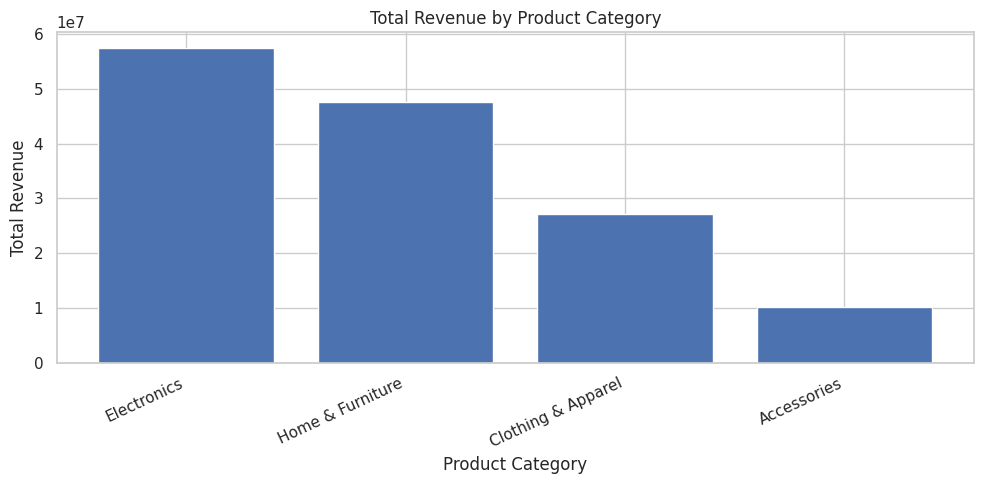

In [ ]:
if "Category" in df.columns and "Revenue" in df.columns:
    revenue_by_category = df.groupby("Category", as_index=False)["Revenue"].sum()
    revenue_by_category = revenue_by_category.sort_values("Revenue", ascending=False)

    plt.figure(figsize=(10, 5))
    plt.bar(revenue_by_category["Category"], revenue_by_category["Revenue"])
    plt.title("Total Revenue by Product Category")
    plt.xlabel("Product Category")
    plt.ylabel("Total Revenue")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Category or Revenue column not found; chart skipped.")

### **11. Step 8 - Region-Wise Sales Analysis**

Compare sales across regions to understand where the business earns more revenue. This section runs if the dataset contains a 'Region' column.

Revenue by region:


,Region,Revenue
1,East,44980048.22
3,West,36242841.73
0,Centre,36081894.34
2,South,25102960.64


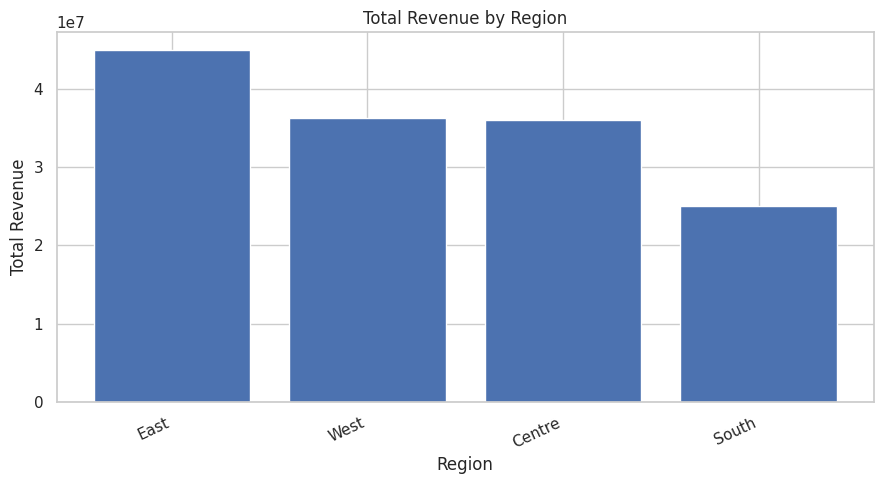

In [ ]:
if "Region" in df.columns and "Revenue" in df.columns:
    region_sales = (
        df.groupby("Region", as_index=False)["Revenue"]
          .sum()
          .sort_values("Revenue", ascending=False)
    )
    print("Revenue by region:")
    display(region_sales)
    print("\n")

    plt.figure(figsize=(9, 5))
    plt.bar(region_sales["Region"], region_sales["Revenue"])
    plt.title("Total Revenue by Region")
    plt.xlabel("Region")
    plt.ylabel("Total Revenue")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Region or Revenue column not found; regional analysis skipped.")

## **12. Step 9 - Monthly Sales Trend**

Convert order dates into monthly periods and calculate monthly revenue. A line chart helps identify changes in sales over time.

Monthly revenue:


,Month,Revenue
0,2023-01-01,4379894.64
1,2023-02-01,2769477.21
2,2023-03-01,3885192.59
3,2023-04-01,4347474.27
4,2023-05-01,4848240.62
5,2023-06-01,4688298.85
6,2023-07-01,4515605.37
7,2023-08-01,4379811.63
8,2023-09-01,4622595.68
9,2023-10-01,8677394.98


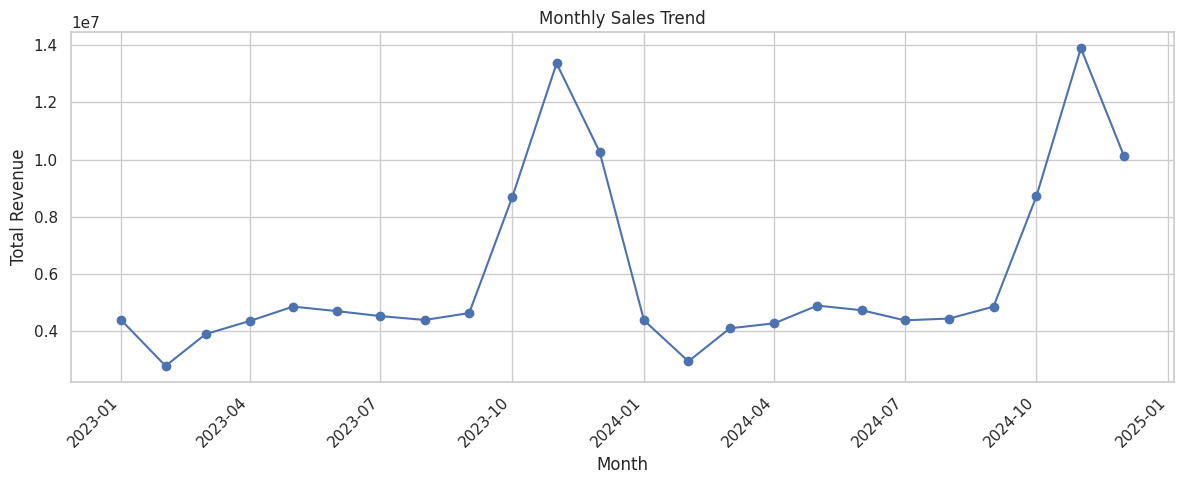

In [ ]:
if "Order_Date" in df.columns and "Revenue" in df.columns:
    dated_df = df.dropna(subset=["Order_Date"]).copy()
    dated_df["Month"] = dated_df["Order_Date"].dt.to_period("M").dt.to_timestamp()

    monthly_sales = (
        dated_df.groupby("Month", as_index=False)["Revenue"]
                .sum()
                .sort_values("Month")
    )

    print("Monthly revenue:")
    display(monthly_sales.head(12))
    print("\n")

    # Create a line chart for monthly revenue
    plt.figure(figsize=(12, 5))
    plt.plot(monthly_sales["Month"], monthly_sales["Revenue"], marker="o")
    plt.title("Monthly Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Total Revenue")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Order_Date or Revenue column not found; monthly trend skipped.")

## **13. Step 10 - Transaction Distribution by Category**

A count plot displays the number of records for each product category. This shows how the dataset transactions are distributed across categories. Each row is treated as one transaction record.

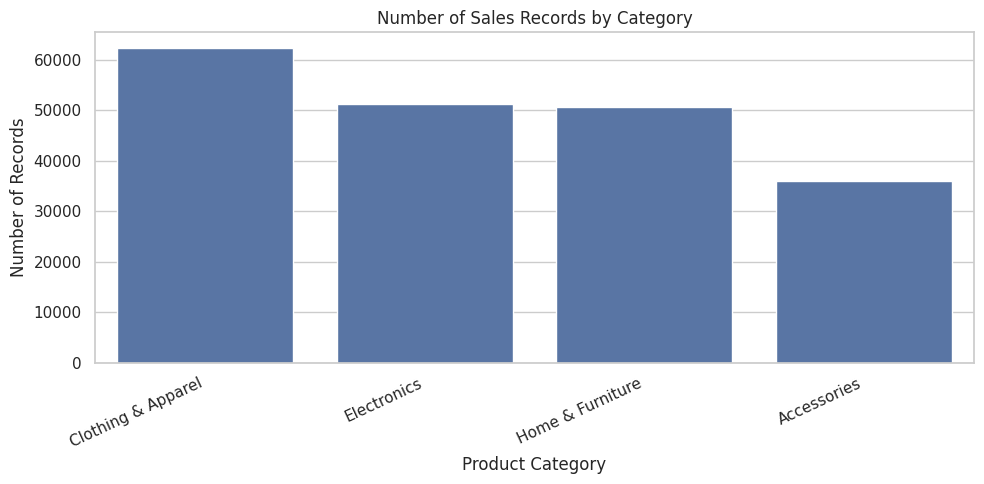

In [ ]:
if "Category" in df.columns:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x="Category", order=df["Category"].value_counts().index)
    plt.title("Number of Sales Records by Category")
    plt.xlabel("Product Category")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Category column not found; count plot skipped.")

## **14. Step 11 - Top-Selling Products**

Identify products with the highest total revenue. This can help the business understand which products contribute strongly to revenue.

Top 10 products by total revenue:


,Product_Name,Revenue
38,Tempur-Pedic Mattress,9061755.86
21,Instant Pot,8903475.26
26,MacBook Air,7362516.81
1,Apple Watch,6834472.35
2,Apple iPhone 14,5740819.18
48,iPad Pro,5574458.89
22,KitchenAid Mixer,4989740.69
36,Storage Rack,4463941.27
7,Brooklinen Sheets,3981027.44
33,Samsung Galaxy S23,3851240.02


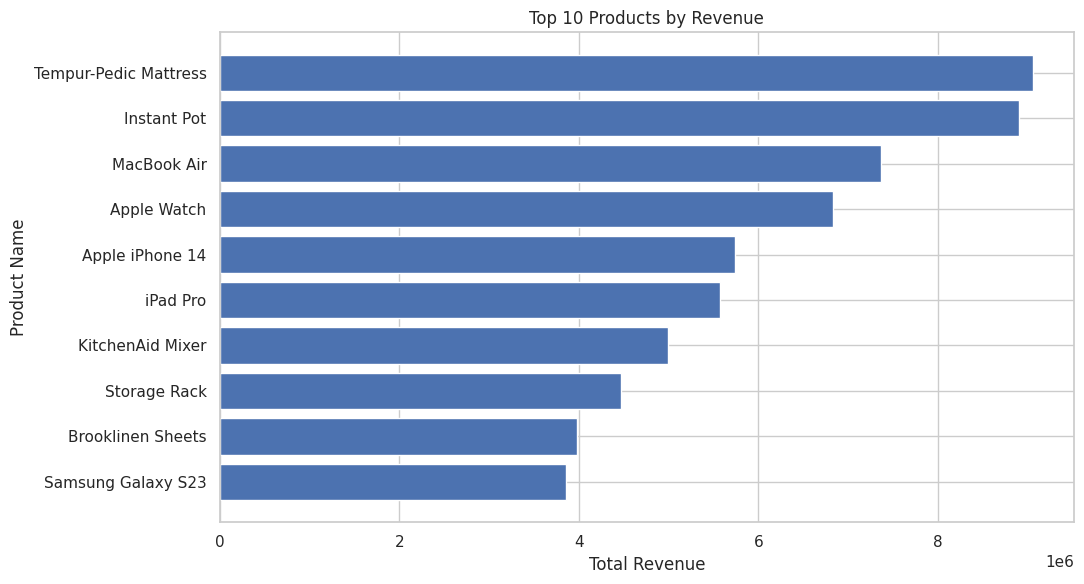

In [ ]:
if "Product_Name" in df.columns and "Revenue" in df.columns:
    top_products = (
        df.groupby("Product_Name", as_index=False)["Revenue"]
          .sum()
          .sort_values("Revenue", ascending=False)
          .head(10)
    )
    print("Top 10 products by total revenue:")
    display(top_products)
    print("\n")

    plt.figure(figsize=(11, 6))
    plt.barh(top_products["Product_Name"][::-1], top_products["Revenue"][::-1])
    plt.title("Top 10 Products by Revenue")
    plt.xlabel("Total Revenue")
    plt.ylabel("Product Name")
    plt.tight_layout()
    plt.show()
else:
    print("Product_Name or Revenue column not found; top-product analysis skipped.")

## **15. Step 12 — Key Findings**

Run this cell to produce data-based findings. The exact values and rankings are calculated from the dataset.

In [ ]:
print("KEY FINDINGS")
print("-" * 50)

if "Revenue" in df.columns:
    print(f"1. Total revenue recorded in the dataset is {df['Revenue'].sum():,.2f}.")
    print("\n")
    print(f"2. Average revenue per record is {df['Revenue'].mean():,.2f}.")
    print("\n")

if "Profit" in df.columns:
    print(f"3. Total profit recorded in the dataset is {df['Profit'].sum():,.2f}.")
    print("\n")

if "Quantity" in df.columns:
    print(f"4. Total quantity sold is {df['Quantity'].sum():,.0f}.")
    print("\n")

if "Category" in df.columns and "Revenue" in df.columns:
    category_totals = df.groupby("Category")["Revenue"].sum().sort_values(ascending=False)
    print(f"5. Highest-revenue category: {category_totals.index[0]} ({category_totals.iloc[0]:,.2f}).")
    print("\n")

    print(f"6. Lowest-revenue category: {category_totals.index[-1]} ({category_totals.iloc[-1]:,.2f}).")
    print("\n")

if "Region" in df.columns and "Revenue" in df.columns:
    region_totals = df.groupby("Region")["Revenue"].sum().sort_values(ascending=False)
    print(f"7. Highest-revenue region: {region_totals.index[0]} ({region_totals.iloc[0]:,.2f}).")
    print("\n")

if "Order_Date" in df.columns and "Revenue" in df.columns:
    temp = df.dropna(subset=["Order_Date"]).copy()
    if not temp.empty:
        temp["Month"] = temp["Order_Date"].dt.to_period("M")
        monthly = temp.groupby("Month")["Revenue"].sum().sort_values(ascending=False)
        print(f"8. Highest-revenue month: {monthly.index[0]} ({monthly.iloc[0]:,.2f}).")
        print("\n")

KEY FINDINGS
--------------------------------------------------
1. Total revenue recorded in the dataset is 142,407,744.93.


2. Average revenue per record is 712.04.


3. Total profit recorded in the dataset is 31,548,608.13.


4. Total quantity sold is 370,800.


5. Highest-revenue category: Electronics (57,485,698.06).


6. Lowest-revenue category: Accessories (10,113,254.61).


7. Highest-revenue region: East (44,980,048.22).


8. Highest-revenue month: 2024-11 (13,899,671.91).




## **16. Conclusion**

This project uses Python, Pandas, Matplotlib, and Seaborn to inspect, clean, analyze, and visualize a product sales dataset. Overall performance is measured using revenue, profit, and quantity sold. Category-wise, region-wise, monthly, and product-level analysis helps identify important sales patterns and areas for further business investigation.

**Business recommendations:**
1. Review the categories and products with the highest revenue to understand what drives sales.
2. Investigate lower-performing categories and regions before making pricing or marketing changes.
3. Use the monthly sales trend to plan inventory and promotions around periods of stronger or weaker sales.
4. Consider both revenue and profit before deciding which products to promote, because high revenue does not always mean high profit.
5. Continue updating the analysis as new sales records become available.